# Baselines: SVM and logistic regression for ASD classification

**Question:** before any graph neural network, how well does a simple model do when it
treats each brain's connectivity as one flat list of numbers?

**Data:** ABIDE I, CPAC pipeline, band-pass filtered, CC200 atlas.
**Protocols:** stratified 10-fold CV (5 repeats) and leave-one-site-out (LOSO).
**Metrics:** balanced accuracy (primary), accuracy, sensitivity, specificity, F1, AUC.

Sections 1-3 run live (about a minute). Sections 4-6 read the full saved runs in
`results/runs/*.json`, produced by `make baselines`.

1. The cohort after quality control
2. What one brain looks like as features
3. **Live demo:** 5-fold SVM and logistic regression, plus the label-shuffle check
4. Full results under both protocols
5. Unseen scanners: per-site results
6. Are the differences significant?

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
import os
os.chdir(ROOT)  # the package reads data/ and results/ relative to the repo root

from asdgnn.data.connectivity import ConnectivityTransformer
from asdgnn.data.loading import load_cohort
from asdgnn.models.classical import build_classical, decision_scores
from asdgnn.train.metrics import compute_all
from asdgnn.train.splits import build_splits

pd.set_option("display.width", 160, "display.max_columns", 40)
FIGS = ROOT / "results/figures/presentation"


def show_fig(name, width=900):
    p = FIGS / name
    if p.exists():
        display(Image(filename=str(p), width=width))
    else:
        display(Markdown(f"_missing `{name}`: run `python scripts/07_baseline_figures.py`_"))

## 1. The cohort after quality control

QC drops subjects with fewer than 100 time points and any region that is flat (zero
variance) in any subject. Both rules are applied once, before any split, and do not
look at diagnosis.

In [2]:
ts_list, pheno = load_cohort("cc200")
y = pheno["y"].to_numpy(int)
sites = pheno["SITE_ID"].to_numpy()

display(Markdown(
    f"**{len(pheno)} subjects** ({y.sum()} ASD, {(y == 0).sum()} control) · "
    f"**{ts_list[0].shape[1]} regions** · **{pheno.SITE_ID.nunique()} sites** · "
    f"time points per scan: {min(t.shape[0] for t in ts_list)}–{max(t.shape[0] for t in ts_list)}"
))

dropped = json.loads((ROOT / "results/qc/dropped.json").read_text())
reasons = pd.Series(dropped["dropped_subjects"]).str.replace(r"\(.*\)", "", regex=True)
display(Markdown(
    f"Dropped **{dropped['n_in'] - dropped['n_out']}** subjects "
    f"({', '.join(f'{n}× {r}' for r, n in reasons.value_counts().items())}) "
    f"and **{len(dropped['dropped_rois'])}** flat regions "
    f"({dropped['n_rois_in']} → {dropped['n_rois_out']})."
))

per_site = (pheno.groupby("SITE_ID")["y"].agg(n="size", ASD="sum")
            .assign(control=lambda d: d.n - d.ASD).sort_values("n", ascending=False))
per_site.T

**846 subjects** (391 ASD, 455 control) · **179 regions** · **19 sites** · time points per scan: 116–316

Dropped **25** subjects (25× too_few_timepoints) and **21** flat regions (200 → 179).

SITE_ID,NYU,UM_1,USM,UCLA_1,PITT,MAX_MUN,TRINITY,YALE,UM_2,KKI,LEUVEN_1,LEUVEN_2,OLIN,SDSU,SBL,STANFORD,UCLA_2,CALTECH,CMU
n,172,86,67,64,50,46,44,41,34,33,28,28,28,27,26,25,21,15,11
ASD,74,34,43,37,24,19,19,22,13,12,14,12,14,8,12,12,11,5,6
control,98,52,24,27,26,27,25,19,21,21,14,16,14,19,14,13,10,10,5


## 2. What one brain looks like as features

Pearson correlation between every pair of regions, Fisher z-transformed. The baselines
read only the upper triangle: 179 × 178 / 2 = 15,931 numbers per subject.

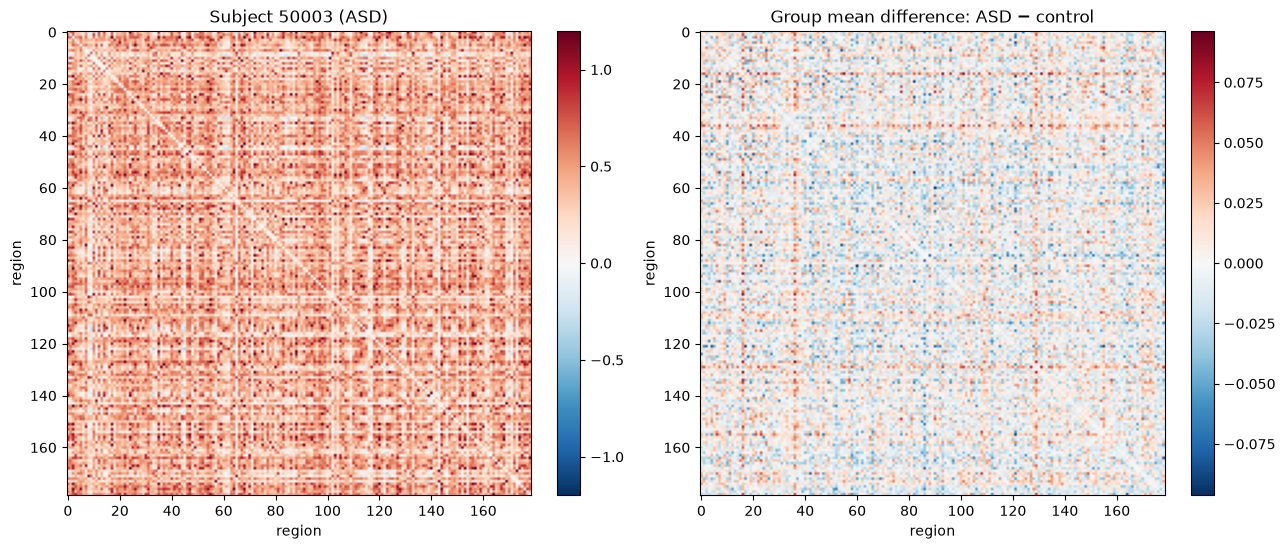

features per subject: 15,931
largest |group difference|: 0.096 (in Fisher-z units), so the signal is small and spread out


In [3]:
ct = ConnectivityTransformer(kind="correlation", vectorize=False).fit(ts_list[:2])
M = ct.transform(ts_list)  # correlation is stateless, so what it was fitted on is irrelevant

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
im = axes[0].imshow(M[0], cmap="RdBu_r", vmin=-1.2, vmax=1.2)
axes[0].set_title(f"Subject {pheno.index[0]} ({'ASD' if y[0] else 'control'})")
fig.colorbar(im, ax=axes[0], fraction=0.046)
d = M[y == 1].mean(0) - M[y == 0].mean(0)
lim = np.abs(d).max()
im2 = axes[1].imshow(d, cmap="RdBu_r", vmin=-lim, vmax=lim)
axes[1].set_title("Group mean difference: ASD − control")
fig.colorbar(im2, ax=axes[1], fraction=0.046)
for a in axes:
    a.set_xlabel("region")
    a.set_ylabel("region")
plt.tight_layout()
plt.show()

iu = np.triu_indices(M.shape[1], k=1)
print(f"features per subject: {len(iu[0]):,}")
print(f"largest |group difference|: {lim:.3f} (in Fisher-z units), so the signal is small and spread out")

## 3. Live demo: 5-fold cross-validation

The whole pipeline (connectivity → standardise → top 2,000 features by ANOVA →
classifier) is one sklearn `Pipeline`, refitted inside every fold on the training
subjects only. This is a smaller, faster version of the full runs in section 4, which
use 10 folds repeated 5 times.

In [4]:
splits = build_splits(y, sites, "kfold", n_splits=5, n_seeds=1)


def run(model, labels):
    rows = []
    for name, tr, te in splits:
        pipe = build_classical({"model": model, "select_k": 2000, "seed": 0})
        pipe.fit([ts_list[i] for i in tr], labels[tr])
        m = compute_all(labels[te], decision_scores(pipe, [ts_list[i] for i in te]))
        rows.append({"fold": name, **{k: m[k] for k in ("bal_acc", "acc", "sens", "spec", "f1", "auc")}})
    return pd.DataFrame(rows).set_index("fold")


live = {}
for model in ("svm", "logreg"):
    t0 = time.time()
    live[model] = run(model, y)
    print(f"{model:7s} done in {time.time() - t0:.0f}s")

summary = pd.DataFrame({m: df.mean() for m, df in live.items()}).T
summary.style.format("{:.3f}")

svm     done in 6s


logreg  done in 4s


,bal_acc,acc,sens,spec,f1,auc
svm,0.667,0.669,0.634,0.699,0.639,0.713
logreg,0.664,0.667,0.632,0.697,0.636,0.723


### The label-shuffle check

Same pipeline, but with the diagnosis labels randomly permuted. If any information from
the test subjects leaked into training, the model would still score above chance. It
should land near 0.50.

In [5]:
shuffled = run("logreg", np.random.RandomState(0).permutation(y))
display(Markdown(
    f"**Shuffled labels: {shuffled.bal_acc.mean():.3f}** balanced accuracy "
    f"vs **{live['logreg'].bal_acc.mean():.3f}** with real labels. "
    + ("Chance level, so there is no leakage." if 0.40 <= shuffled.bal_acc.mean() <= 0.60
       else "**Outside 0.40–0.60: investigate before trusting anything.**")
))

**Shuffled labels: 0.506** balanced accuracy vs **0.664** with real labels. Chance level, so there is no leakage.

## 4. Full results under both protocols

Read from the saved run files: 10-fold CV repeated 5 times (50 folds) and leave-one-site-out
(19 folds, one per site). ± is the standard deviation across folds or sites.

In [6]:
blobs = [json.loads(p.read_text()) for p in sorted((ROOT / "results/runs").glob("*.json"))]
NAMES = {"logreg": "Logistic regression", "svm": "SVM (linear)", "rf": "Random forest", "ridge": "Ridge"}
rows = []
for b in blobs:
    a = b["aggregate"]
    rows.append({
        "model": NAMES.get(b["model"], b["model"]),
        "protocol": {"kfold": "10-fold ×5", "loso": "LOSO"}[b["protocol"]],
        **{k: f"{a[k + '_mean']:.3f} ± {a[k + '_std']:.3f}"
           for k in ("bal_acc", "acc", "sens", "spec", "f1", "auc")},
        "_sort": a["bal_acc_mean"],
    })
results = (pd.DataFrame(rows).sort_values(["protocol", "_sort"], ascending=[True, False])
           .drop(columns="_sort").set_index(["protocol", "model"]))
results

bal_acc            acc           sens           spec             f1            auc
protocol   model                                                                                                        
10-fold ×5 Logistic regression  0.647 ± 0.044  0.649 ± 0.044  0.616 ± 0.066  0.678 ± 0.061  0.618 ± 0.051  0.699 ± 0.045
           Random forest        0.639 ± 0.052  0.648 ± 0.050  0.513 ± 0.086  0.764 ± 0.060  0.572 ± 0.072  0.699 ± 0.053
           SVM (linear)         0.635 ± 0.047  0.637 ± 0.046  0.608 ± 0.079  0.662 ± 0.060  0.606 ± 0.057  0.686 ± 0.046
           Ridge                0.608 ± 0.051  0.611 ± 0.051  0.578 ± 0.072  0.639 ± 0.080  0.578 ± 0.056  0.651 ± 0.051
LOSO       Logistic regression  0.645 ± 0.094  0.652 ± 0.093  0.597 ± 0.160  0.693 ± 0.139  0.599 ± 0.131  0.693 ± 0.100
           Random forest        0.629 ± 0.069  0.631 ± 0.074  0.480 ± 0.244  0.779 ± 0.201  0.505 ± 0.185  0.724 ± 0.084
           SVM (linear)         0.615 ± 0.089  0.622 ± 0.086  0.584 ± 0.147  0.645 ± 0.144  0.576 ± 0.127  0.680 ± 0.100
           Ridge                0.598 ± 0.096  0.600 ± 0.092  0.551 ± 0.122  0.645 ± 0.131  0.551 ± 0.122  0.621 ± 0.103

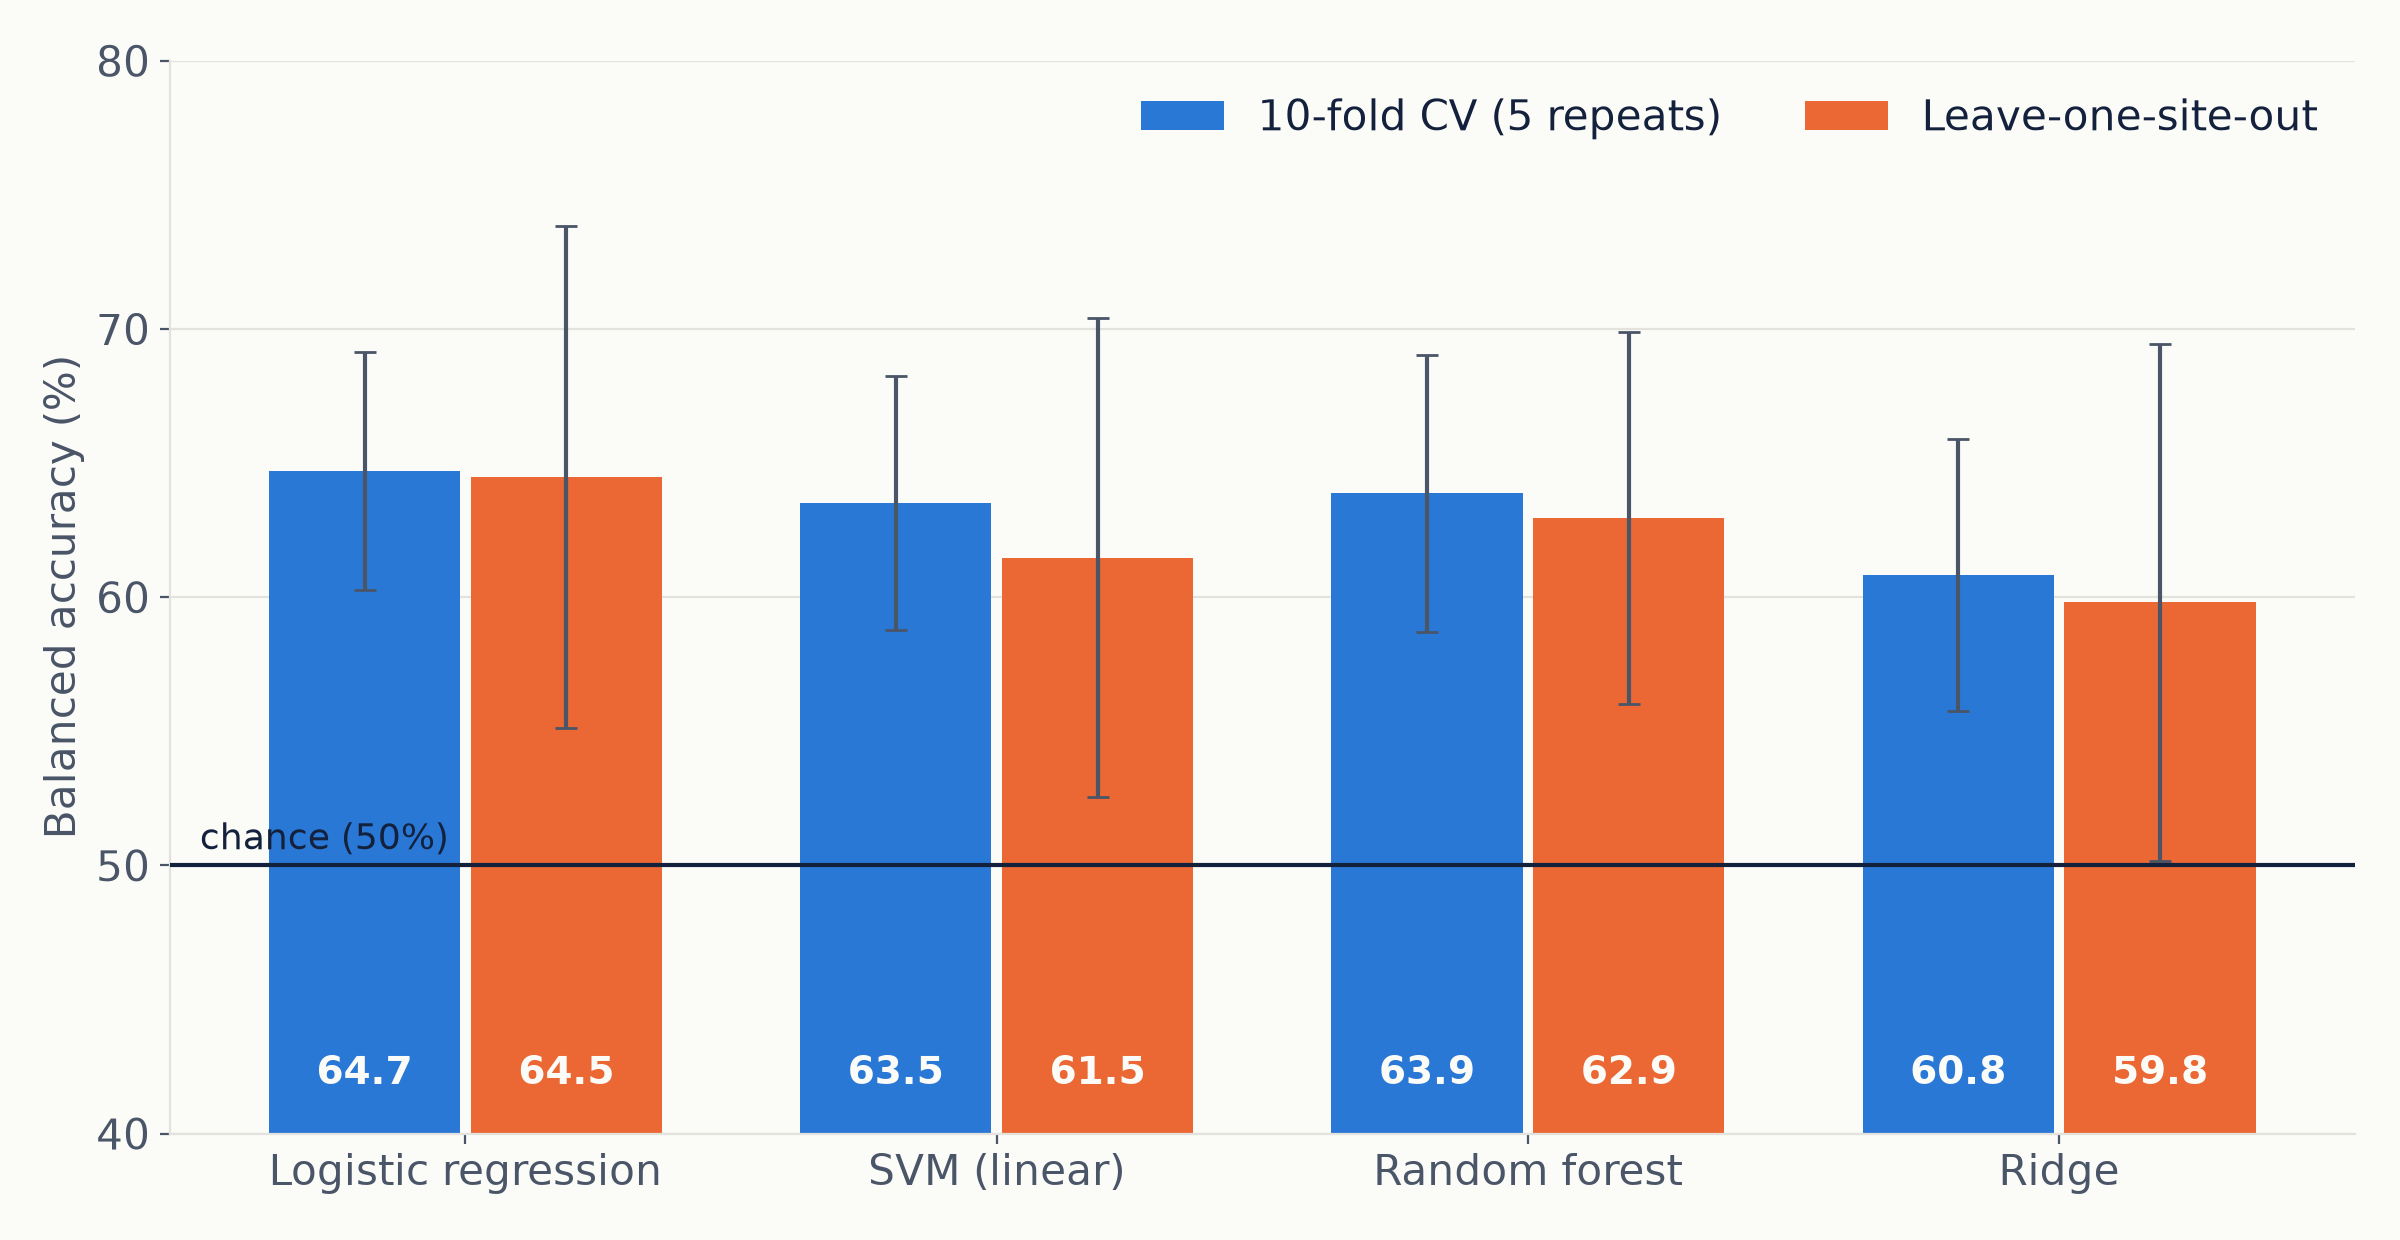

In [7]:
show_fig("bal_acc_bars.png")

## 5. Unseen scanners: per-site results

Under LOSO the model is tested on a site it never saw during training. The average
barely moves, but individual sites swing widely, and small sites swing the most.

Logistic regression: **49.6%** (MAX_MUN) to **85.5%** (UCLA_2) across sites; 1 of 19 sites below chance.

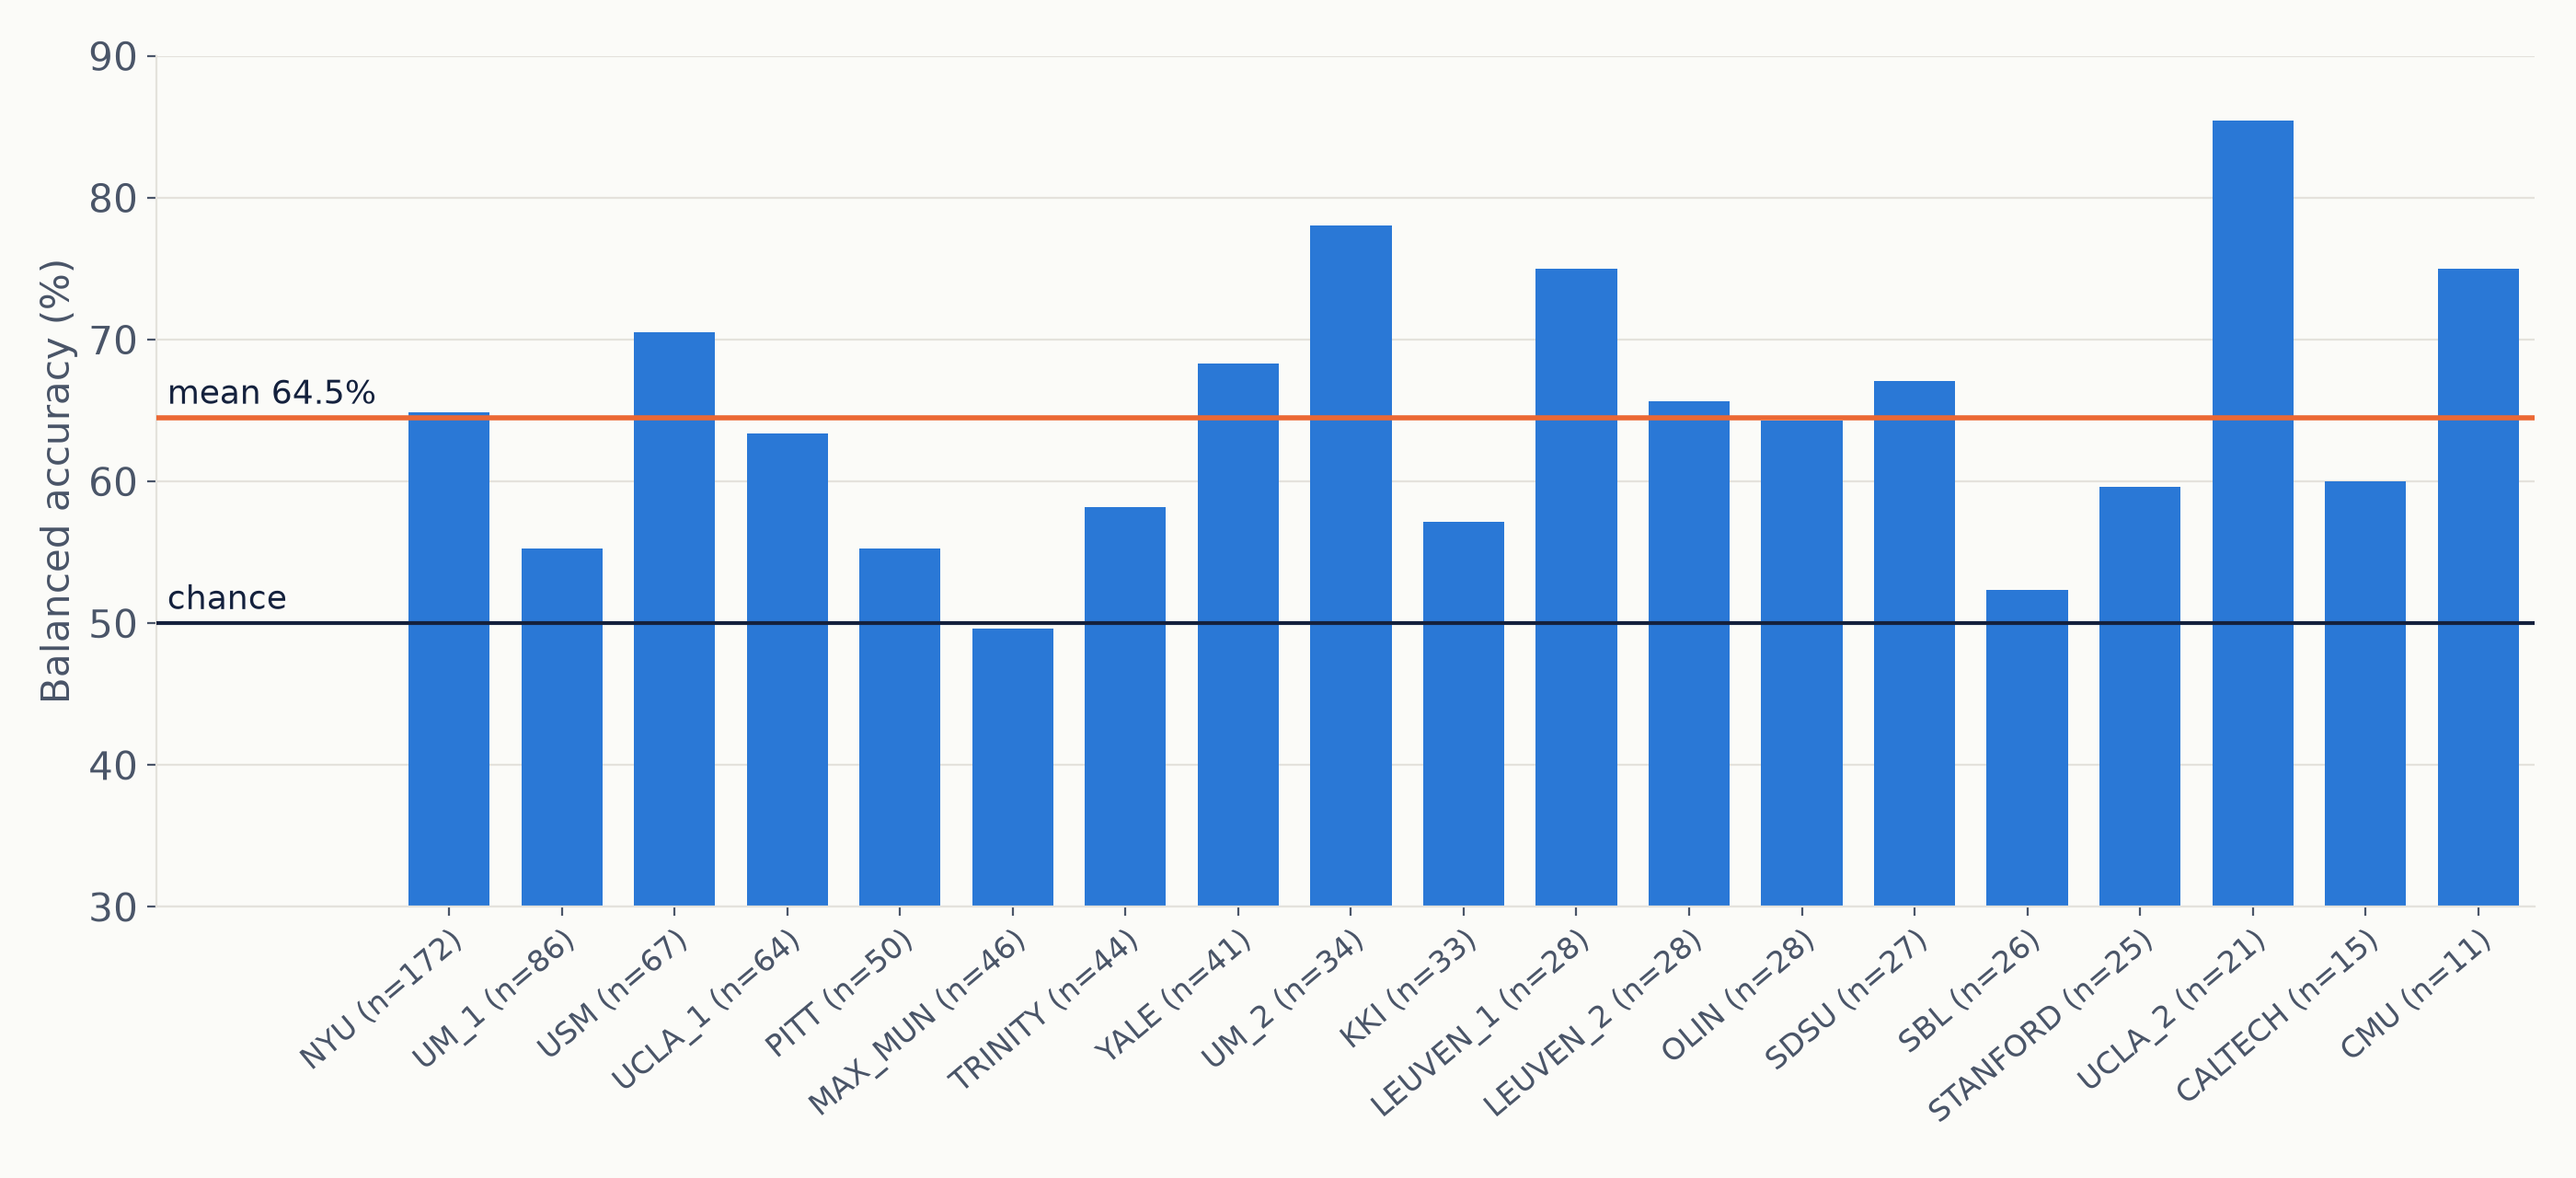

site,NYU,UM_1,USM,UCLA_1,PITT,MAX_MUN,TRINITY,YALE,UM_2,KKI,LEUVEN_1,LEUVEN_2,OLIN,SDSU,SBL,STANFORD,UCLA_2,CALTECH,CMU
n,172.000,86.000,67.000,64.000,50.000,46.000,44.000,41.000,34.000,33.000,28.00,28.000,28.000,27.000,26.000,25.000,21.000,15.00,11.00
bal_acc,0.649,0.553,0.705,0.634,0.553,0.496,0.582,0.683,0.780,0.571,0.75,0.656,0.643,0.671,0.524,0.596,0.855,0.60,0.75
auc,0.730,0.640,0.810,0.677,0.619,0.569,0.640,0.720,0.832,0.627,0.73,0.661,0.689,0.704,0.548,0.744,0.818,0.52,0.90


In [8]:
lr = next(b for b in blobs if b["model"] == "logreg" and b["protocol"] == "loso")
per = pd.DataFrame([{"site": f["fold"], "n": f["metrics"]["n_test"],
                     "bal_acc": f["metrics"]["bal_acc"], "auc": f["metrics"]["auc"]}
                    for f in lr["folds"]]).sort_values("n", ascending=False).set_index("site")
display(Markdown(
    f"Logistic regression: **{per.bal_acc.min():.1%}** ({per.bal_acc.idxmin()}) to "
    f"**{per.bal_acc.max():.1%}** ({per.bal_acc.idxmax()}) across sites; "
    f"{(per.bal_acc < 0.5).sum()} of {len(per)} sites below chance."
))
show_fig("per_site_logreg.png", width=1000)
per.T.round(3)

In [9]:
sanity = json.loads((ROOT / "results/qc/sanity.json").read_text())
display(Markdown(
    f"**Site-control task: {sanity['site_control']['bal_acc']:.3f}** balanced accuracy at "
    "telling one site apart from the rest, using the same features. Scanner identity is "
    "in the data, which is why the ComBat harmonisation comparison is the next step."
))

**Site-control task: 0.638** balanced accuracy at telling one site apart from the rest, using the same features. Scanner identity is in the data, which is why the ComBat harmonisation comparison is the next step.

## 6. Are the differences significant?

Every model used the same cached split file and saved a probability for every subject,
so models can be compared on the same people.

- **DeLong test:** compares two ROC curves on paired predictions.
- **Corrected resampled t-test:** compares fold scores, accounting for folds sharing
  training data (a plain paired t-test is over-confident here).

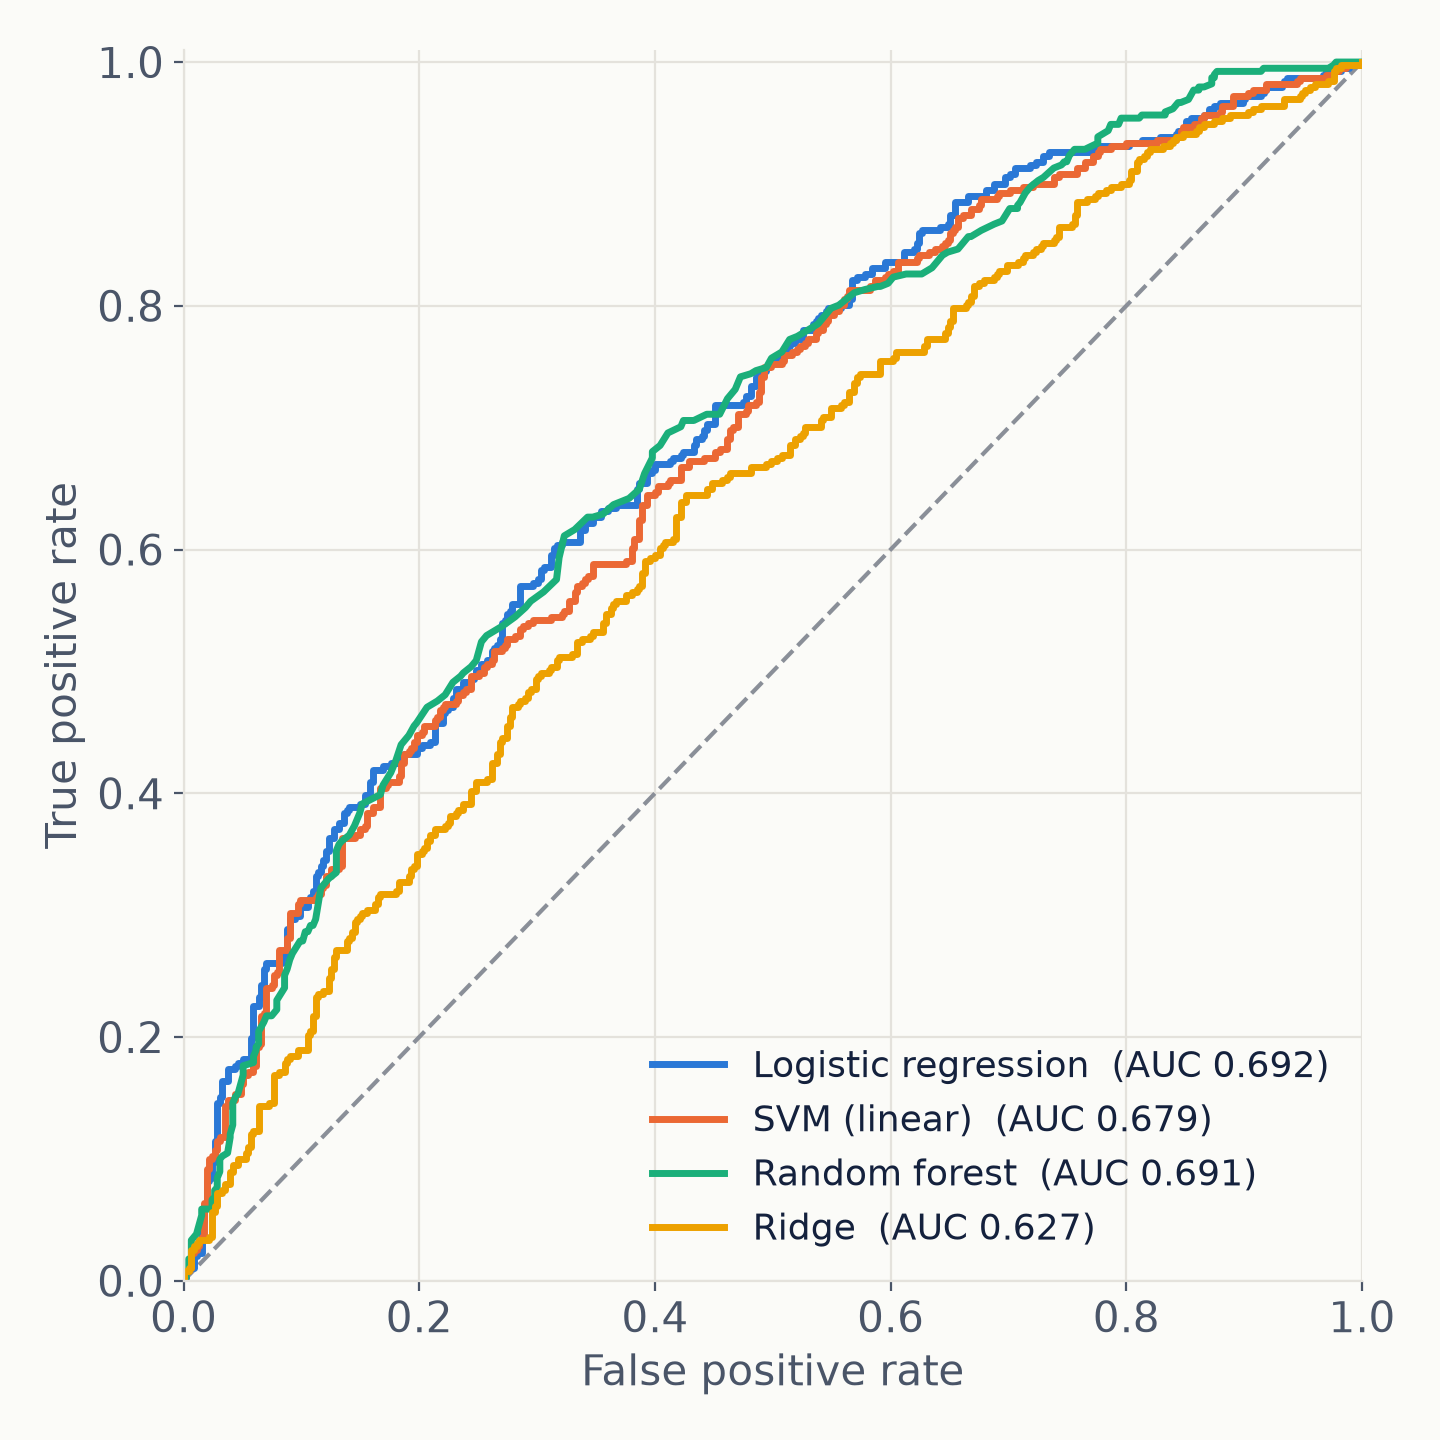

### kfold

,auc_a,auc_b,delta,p,corrected_t_p
logreg_vs_rf,0.696,0.690,+0.006,0.74,0.47
logreg_vs_ridge,0.696,0.653,+0.043,8.9e-05,3.6e-05
logreg_vs_svm,0.696,0.683,+0.013,1.1e-05,0.016
rf_vs_ridge,0.690,0.653,+0.037,0.08,0.018
rf_vs_svm,0.690,0.683,+0.007,0.71,0.75
ridge_vs_svm,0.653,0.683,-0.030,0.0022,0.0044


### loso

,auc_a,auc_b,delta,p,corrected_t_p
logreg_vs_rf,0.692,0.691,+0.001,0.94,0.68
logreg_vs_ridge,0.692,0.627,+0.065,1e-08,0.14
logreg_vs_svm,0.692,0.679,+0.013,6.6e-05,0.086
rf_vs_ridge,0.691,0.627,+0.064,0.0031,0.47
rf_vs_svm,0.691,0.679,+0.011,0.55,0.7
ridge_vs_svm,0.627,0.679,-0.053,3.1e-07,0.52


In [10]:
show_fig("roc_loso.png", width=560)
for protocol in ("kfold", "loso"):
    s = json.loads((ROOT / f"results/tables/stats_{protocol}.json").read_text())
    t = pd.DataFrame(s["delong"]).T[["auc_a", "auc_b", "delta", "p"]]
    t["corrected_t_p"] = pd.DataFrame(s["corrected_ttest"]).T["p"]
    display(Markdown(f"### {protocol}"))
    display(t.style.format({"auc_a": "{:.3f}", "auc_b": "{:.3f}", "delta": "{:+.3f}",
                            "p": "{:.2g}", "corrected_t_p": "{:.2g}"}))

## Takeaways

- **Logistic regression is the strongest baseline:** about 0.65 balanced accuracy under
  both protocols. That is the bar the GNNs must clear.
- **It beats SVM by a small but significant margin** (DeLong p < 0.001 under both
  protocols).
- **Unseen scanners cost almost nothing on average**, but per-site performance ranges
  from chance to about 85%.
- **Random forest's balanced accuracy hides a bias:** it finds under half of the ASD
  cases.
- **The pipeline is honest:** shuffled labels score at chance, and the leakage test suite
  passes.